In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

In [2]:
emotion_dataset = load_dataset("dair-ai/emotion")

train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

valid_text = emotion_dataset['validation']['text']
valid_label = emotion_dataset['validation']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_name = emotion_dataset['train'].features['label'].names
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [4]:
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label': [label_name[i] for i in train_label]
    }
)

df_valid = pd.DataFrame(
    {
        'text': valid_text,
        'label': [label_name[i] for i in valid_label]
    }
)

df_test = pd.DataFrame(
    {
        'text': test_text,
        'label': [label_name[i] for i in test_label]
    }
)


In [5]:
df_train["label"].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

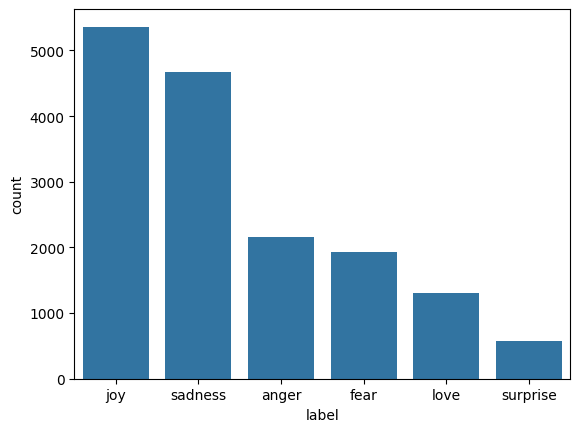

In [6]:
#Checking the Model Biasing
sns.countplot(x='label', data=df_train, order=df_train["label"].value_counts().index)

In [7]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [8]:
from pygments.token import Token
'''
Tokenizing
lower token high occurance
higher token low occurance
'''
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

Tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
Tokenizer.fit_on_texts(df_train['text'])

train_sequences = Tokenizer.texts_to_sequences(df_train['text'])
valid_sequences = Tokenizer.texts_to_sequences(df_valid['text'])
test_sequences = Tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences, padding='post', maxlen=50, truncating='post')
padded_valid_sequences = pad_sequences(valid_sequences, padding='post', maxlen=50, truncating='post')
padded_test_sequences = pad_sequences(test_sequences, padding='post', maxlen=50, truncating='post')

train_labels = np.array(train_label)
valid_labels = np.array(valid_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(Tokenizer.word_index)}")
print(f"Number of Classes: {num_classes}")
print(f"Max Sequence Length: {padded_train_sequences.shape[1]}")


Vocabulary Size: 15213
Number of Classes: 6
Max Sequence Length: 50


In [9]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)
class_weights_dict = dict(enumerate(class_weights))
class_weights_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, LSTM, GRU, Dense, Dropout

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(num_classes, activation='softmax'), #Output Layer
])

rnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
rnn_model_history = rnn_model.fit(
    padded_train_sequences,
    train_labels,
    epochs=20,
    validation_data=(padded_valid_sequences,valid_labels),
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
    )

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_labels)
print(f"Test Loss: {rnn_loss}")
print(f"Test Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1352 - loss: 1.8246 - val_accuracy: 0.0495 - val_loss: 1.8123
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1407 - loss: 1.8072 - val_accuracy: 0.2585 - val_loss: 1.8005
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1433 - loss: 1.8048 - val_accuracy: 0.0455 - val_loss: 1.7868
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0465 - loss: 1.8097
Test Loss: 1.8097130060195923
Test Accuracy: 0.04650000110268593


In [17]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(num_classes, activation='softmax'), #Output Layer
])

lstm_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

lstm_model_history = lstm_model.fit(
    padded_train_sequences,
    train_labels,
    epochs=20,
    validation_data=(padded_valid_sequences,valid_labels),
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
    )

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_labels)
print(f"Test Loss: {lstm_loss}")
print(f"Test Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1566 - loss: 1.7954 - val_accuracy: 0.3520 - val_loss: 1.7721
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1776 - loss: 1.7938 - val_accuracy: 0.0405 - val_loss: 1.8073
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1498 - loss: 1.7935 - val_accuracy: 0.1105 - val_loss: 1.7941
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3480 - loss: 1.7714
Test Loss: 1.7714476585388184
Test Accuracy: 0.3479999899864197


In [18]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(num_classes, activation='softmax'), #Output Layer
])

gru_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

gru_model_history = gru_model.fit(
    padded_train_sequences,
    train_labels,
    epochs=20,
    validation_data=(padded_valid_sequences,valid_labels),
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
    )

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_labels)
print(f"Test Loss: {gru_loss}")
print(f"Test Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1411 - loss: 1.7961 - val_accuracy: 0.1375 - val_loss: 1.7735
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1489 - loss: 1.7955 - val_accuracy: 0.1385 - val_loss: 1.7887
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1502 - loss: 1.7951 - val_accuracy: 0.0415 - val_loss: 1.8091
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1375 - loss: 1.7719
Test Loss: 1.7719388008117676
Test Accuracy: 0.13750000298023224


In [20]:
result_df = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
}).sort_values(by='Test Accuracy', ascending=False)

result_df

,Model,Test Loss,Test Accuracy
1,LSTM,1.771448,0.3480
2,GRU,1.771939,0.1375
0,RNN,1.809713,0.0465


In [23]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax'), #Output Layer
])

BiGRU.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
BiGRU_history = BiGRU.fit(
    padded_train_sequences,
    train_labels,
    epochs=20,
    validation_data=(padded_valid_sequences,valid_labels),
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
    )

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.5591 - loss: 1.0428 - val_accuracy: 0.8795 - val_loss: 0.3968
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9124 - loss: 0.2574 - val_accuracy: 0.9125 - val_loss: 0.2440
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9427 - loss: 0.1563 - val_accuracy: 0.9230 - val_loss: 0.2366
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9603 - loss: 0.1130 - val_accuracy: 0.9185 - val_loss: 0.2552
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9670 - loss: 0.0897 - val_accuracy: 0.9265 - val_loss: 0.2518
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9749 - loss: 0.0726 - val_accuracy: 0.9265 - val_loss: 0.2538


In [25]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequences, test_labels)
print(f"Test Loss: {BiGRU_loss}")
print(f"Test Accuracy: {BiGRU_accuracy}")
#

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9105 - loss: 0.2543
Test Loss: 0.2542736232280731
Test Accuracy: 0.9104999899864197


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


<Axes: >

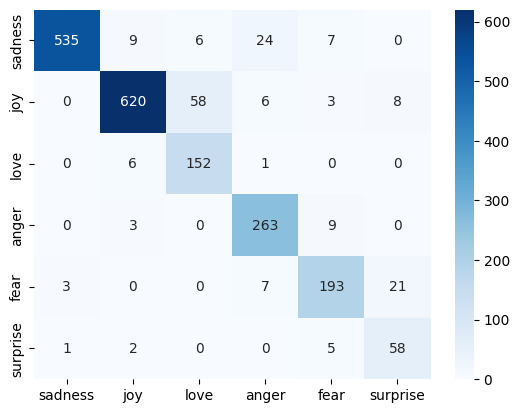

In [29]:
from sklearn.metrics import classification_report, confusion_matrix

BiGRU_pred = BiGRU.predict(padded_test_sequences)
BiGRU_pred = np.argmax(BiGRU_pred, axis=1)

sns.heatmap(confusion_matrix(test_labels, BiGRU_pred), annot=True, fmt='d', cmap='Blues', xticklabels=label_name, yticklabels=label_name)


In [34]:
sample_texts = [
    "I finally received the promotion I’ve been working toward for two whole years!",
    "I don't know what to do, I feel completely lost and alone since they left.",
    "I cannot believe you shared my private information without asking me first, that is completely unacceptable.",
    "My heart is racing and I keep hearing strange noises coming from the basement in the dark.",
    "The package is scheduled to be delivered between 2:00 PM and 5:00 PM tomorrow afternoon.",
    "I am very happy today.",
    "I feel so sad.",
    "This makes me so angry.",
    "I am very scared right now.",
    "The table is made of wood."
]

sample_sequences = Tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, padding='post', maxlen=50, truncating='post')

sample_predictions = BiGRU.predict(sample_padded_sequences)
sample_predictions = np.argmax(sample_predictions, axis=1)

for i in range(len(sample_texts)):
    print(f"Text: {sample_texts[i]}")
    print(f"Predicted Label: {label_name[sample_predictions[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Text: I finally received the promotion I’ve been working toward for two whole years!
Predicted Label: love
Text: I don't know what to do, I feel completely lost and alone since they left.
Predicted Label: sadness
Text: I cannot believe you shared my private information without asking me first, that is completely unacceptable.
Predicted Label: anger
Text: My heart is racing and I keep hearing strange noises coming from the basement in the dark.
Predicted Label: fear
Text: The package is scheduled to be delivered between 2:00 PM and 5:00 PM tomorrow afternoon.
Predicted Label: fear
Text: I am very happy today.
Predicted Label: joy
Text: I feel so sad.
Predicted Label: sadness
Text: This makes me so angry.
Predicted Label: anger
Text: I am very scared right now.
Predicted Label: fear
Text: The table is made of wood.
Predicted Label: joy


In [42]:
import os
import pickle

model_dir = "Artifacts"
os.makedirs(model_dir, exist_ok=True)

#Save Model
BiGRU.save(os.path.join(model_dir, "BiGRU_model.keras"))

#Save Tokenizer
with open(os.path.join(model_dir, "tokenizer.pkl"), "wb") as f:
    pickle.dump(Tokenizer, f)
